# Coursework 1
**Replace CID in the file name with your CID**

# Outline


- [Task 1](#task-1): Multi-class classification with Decision Trees and Random Forests <a name="index-task-1"></a>
  - [(1.1)](#task-11) <a name="index-task-11"></a>
  - [(1.2)](#task-12) <a name="index-task-12"></a>
  - [(1.3)](#task-13) <a name="index-task-13"></a>
  - [(1.4)](#task-14) <a name="index-task-14"></a>
- [Task 2](#task-2): Binary classification with the Huberised Support Vector Machine <a name="index-task-2"></a>
  - [(2.1)](#task-21) <a name="index-task-21"></a>
  - [(2.2)](#task-22)  <a name="index-task-22"></a>
- [Task 3](#task-3): Regression with the Multi-Layer Perceptron <a name="index-task-3"></a>
  - [(3.1)](#task-31) <a name="index-task-31"></a>
  - [(3.2)](#task-32)  <a name="index-task-32"></a>



---



<a name="task-1"></a>

# Task 1: Multi-class classification with Decision Trees and Random Forests  [(index)](#index-task-1)

In [46]:
# we first import packages and libraries needed
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# We set a global configuration for matplotlib to obtain well-readable plots
SMALL_SIZE = 12
MEDIUM_SIZE = 16
BIGGER_SIZE = 20

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# fixing random generator for reproducibility
rng = np.random.default_rng(0)

<a name="task-11"></a>

## (1.1) [(index)](#index-task-11)

In [47]:
airfield_stats_test = pd.read_csv('airfield_statistics_test.csv')
airfield_stats_train = pd.read_csv('airfield_statistics_train.csv')

X_train = airfield_stats_train.iloc[:, :6].values  
y_train = airfield_stats_train.iloc[:, 6].values   

X_test = airfield_stats_test.iloc[:, :6].values  
y_test = airfield_stats_test.iloc[:, 6].values  

cat_columns_dict = {i: False for i in range(X_train.shape[1])} 

feature_names = airfield_stats_train.columns[:6].tolist()  


In [48]:
X_train

array([[  24. ,   59.9,   58.5,   79.3,    5.1, 1347. ],
       [   0. ,   66.7,  158.3,   61. ,    3.5, 1306. ],
       [   0. ,   39.5,  194.6,   57.9,    3.2, 1284. ],
       ...,
       [   0. ,   17.1,  166.7,   62.4,    1.9, 1300. ],
       [   3. ,   84.8,   81.3,   68.3,    4.3, 1300. ],
       [   0. ,   16.4,  176.9,   57. ,    2.6, 1339. ]])

In [49]:
def gini_index(y):
    """
    Arguments:
        y: vector of training labels, of shape (N,).
    Returns:
        (float): the GINI-index for the labels in a given region.
    """

    # Count occurrences of each unique label in y
    unique_labels, counts = np.unique(y, return_counts=True)

    # Compute probabilities for each label
    p = counts / len(y)

    # Compute the sum of squared probabilities
    sum_p_squared = np.sum(p**2)

    # Return GINI-Index
    return 1 - sum_p_squared


def split_samples(X, y, column, value, categorical):
    """
    Return the split of data whose column-th feature:
      1. equals value, in case `column` is categorical, or
      2. less than value, in case `column` is not categorical (i.e. numerical)

    Arguments:
        X: training features, of shape (N, p).
        y: vector of training labels, of shape (N,).
        column: the column of the feature for splitting.
        value: splitting threshold  the samples
        categorical: boolean value indicating whether column is a categorical variable or numerical.
    Returns:
        tuple(np.array, np.array, np.array): tuple of the left split data (X_l, y_l).
        tuple(np.array, np.array, np.array): tuple of the right split data (X_l, y_l)
    """

    if categorical:
        left_mask =(X[:, column] == value)
    else:
        left_mask = (X[:, column] < value)

    # Using the binary masks `left_mask`, we split X, y, and sample_weights.
    X_l, y_l = X[left_mask, :], y[left_mask] # <- SOLUTION
    X_r, y_r = X[~left_mask, :], y[~left_mask] # <- SOLUTION

    return (X_l, y_l), (X_r, y_r)

def gini_split_value(X, y, column, categorical):
    """
    Calculate the GINI-index based on `column` with the split that minimizes the GINI-index.
    Arguments:
        X: training features, of shape (N, p).
        y: vector of training labels, of shape (N,).
        column: the column index of the feature for calculating. 0 <= column < p
        categorical: boolean value indicating whether column is a categorical variable or numerical.
    Returns:
        (float, float): the resulted GINI-index and the corresponding value used in splitting.
    """

    unique_vals = np.unique(X[:, column])

    assert len(unique_vals) > 1, f"There must be more than one distinct feature value. Column: {column}."

    gini_index_val, threshold = np.inf, None

    # iterate over all unique values of the i-th feature
    for value in unique_vals:
        # Split the samples into left and right subsets based on the current value
        (X_l, y_l), (X_r, y_r) = split_samples(X, y, column, value, categorical) ## <-- SOLUTION

        # check if one of the subsets is empty (invalid split)
        if len(y_l) == 0 or len(y_r) == 0:
            continue

        # calculate the proportion of samples on the left and right sides
        p_left = len(y_l)/(len(y_l)+len(y_r))
        p_right = len(y_r)/(len(y_l)+len(y_r))

        # compute the GINI index for the left and right subsets
        new_cost = p_left * gini_index(y_l) + p_right * gini_index(y_r) ## <-- SOLUTION

        # update the minimum GINI index and the threshold if this split is better
        if new_cost < gini_index_val:
              gini_index_val, threshold = new_cost, value

    return gini_index_val, threshold

def gini_split(X, y, cat_columns_dict):
    """
    Choose the best feature to split according to criterion.
    Args:
        X: training features, of shape (N, p).
        y: vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
    Returns:
        (float, int, float): the minimal Gini index found, the best feature index and value used in splitting.
        If the feature index is None, then no valid split for the current Node.
    """

    # Initialize `split_column` to None, so if None returned this means there is no valid split at the current node.
    min_gini_index = np.inf
    split_column = None
    split_val = np.nan

    for column, categorical in cat_columns_dict.items():
        # skip column if samples are not separable by that column.
        if len(np.unique(X[:, column])) < 2:
            continue
        gini_index, current_split_val = gini_split_value(X, y, column, categorical)  ## <-- SOLUTION


        if gini_index < min_gini_index: ## <-- SOLUTION
            # Keep track with:

            # 1. the current minimum gini-index value,
            min_gini_index = gini_index ## <-- SOLUTION

            # 2. corresponding column,
            split_column = column ## <-- SOLUTION

            # 3. corresponding split threshold.
            split_val = current_split_val ## <-- SOLUTION

    return min_gini_index, split_column, split_val

def majority_vote(y):
    """
    Return the label which appears the most in y.
    Args:
        y: vector of training labels, of shape (N,).
    Returns:
        (int): the majority label
    """
    # Find unique labels and their counts
    labels, counts = np.unique(y, return_counts=True)

    # Identify the label with the maximum count
    majority_label = labels[np.argmax(counts)]

    return majority_label

def build_tree(X, y, cat_columns_dict, feature_names, depth, max_depth=10, min_samples_leaf=2):
    """Build the decision tree according to the data.
    Args:
        X: (np.array) training features, of shape (N, p).
        y: (np.array) vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
        feature_names (list): record the name of features in X in the original dataset.
        depth (int): current depth for this node.
        max_depth (int): maximum depth of the tree.
        min_samples_leaf (int): minimum number of samples in a leaf node.
    Returns:
        (dict): a dict denoting the decision tree (binary-tree). Each parent node has seven attributes:
          1. 'feature_name': The column name of the split.
          2. 'feature_index': The column index of the split.
          3. 'value': The value used for the split.
          4. 'categorical': indicator for categorical/numerical variables.
          5. 'majority_label': For leaf nodes, this stores the dominant label. Otherwise, it is None.
          6. 'left': The left sub-tree with the same structure.
          7. 'right' The right sub-tree with the same structure.
    """
    # include a clause for the cases where (i) no feature, (ii) all labels are the same,
    # (iii) depth exceeded, or (iv) X is too small
    if len(np.unique(y))==1 or depth>max_depth or len(X)<=min_samples_leaf:
        return {'majority_label': majority_vote(y)}

    GI, split_index, split_val = gini_split(X, y, cat_columns_dict)  ## <-- SOLUTION

    # If no valid split at this node, use majority vote.
    if split_index is None:
        return {'majority_label': majority_vote(y)}

    categorical = cat_columns_dict[split_index]

    # Split samples (X, y, sample_weights) given column, split-value, and categorical flag.
    (X_l, y_l), (X_r, y_r) = split_samples(X, y, split_index, split_val, categorical) ## <-- SOLUTION
    return {
        'feature_name': feature_names[split_index],
        'feature_index': split_index,
        'value': split_val,
        'categorical': categorical,
        'majority_label': None,
        'left': build_tree(X_l, y_l, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf),
        'right': build_tree(X_r, y_r, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf)
    }

In [50]:
# EDIT THIS FUNCTION
def classify(tree, x):
    """
    Classify a single sample with the fitted decision tree.
    Args:
        x: ((pd.Dataframe) a single sample features, of shape (p,).
    Returns:
        (int): predicted testing sample label.
    """
    if tree['majority_label'] is not None:
        return tree['majority_label']

    elif tree['categorical']:
        if x[tree['feature_index']] == tree['value']:
            # go to left branch
            return classify(tree['left'], x)
        else:
            # go to right branch
            return classify(tree['right'], x)

    else:

        if x[tree['feature_index']] < tree['value']: # <- SOLUTION
            # go to left branch
            return classify(tree['left'], x)  # <- SOLUTION
        else:
            # go to right branch
            return classify(tree['right'], x)  # <- SOLUTION
        
def predict(tree, X):
    """
    Predict classification results for X.
    Args:
        X: (pd.Dataframe) testing sample features, of shape (N, p).
    Returns:
        (np.array): predicted testing sample labels, of shape (N,).
    """
    if len(X.shape) == 1:
        return classify(tree, X)
    else:
        return np.array([classify(tree, x) for x in X])
    
## EDIT THIS FUNCTION
def tree_score(tree, X_test, y_test):
    y_pred = predict(tree, X_test) ## <-- SOLUTION
    return np.mean(y_pred==y_test)

In [51]:
feature_names = airfield_stats_train.columns[:6].tolist()

max_depth = 10
min_samples_leaf = 12

In [52]:
def standardise(X, X_train_=None):
    """Standardise features.

    Parameters:
        X (np.array): Feature matrix.
        X_train_ (np.array): An optional feature matrix to compute the statistics
            from before applying it to X. If None, just use X to compute the statistics.

    Returns:
        X_std (np.array): Standardised feature matrix
    """
    if X_train_ is None:
        X_train_ = X

    mu = np.mean(X_train_, axis=0, keepdims=True) ## <-- SOLUTION
    sigma = np.std(X_train_, axis=0, keepdims=True) ## <-- SOLUTION
    X_std = (X - mu) / sigma ## <-- SOLUTION
    return X_std

In [53]:
#Non standardized section
tree = build_tree(X_train, y_train, cat_columns_dict, feature_names, depth=0, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
print('Training accuracy:', tree_score(tree, X_train, y_train))
print('Test accuracy:', tree_score(tree, X_test, y_test))

Training accuracy: 0.9281961471103327
Test accuracy: 0.8530612244897959


In [54]:
X_train_std=standardise(X_train)
X_test_std=standardise(X_test)
tree = build_tree(X_train_std, y_train, cat_columns_dict, feature_names, depth=0, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
print('Training accuracy:', tree_score(tree, X_train_std, y_train))
print('Test accuracy:', tree_score(tree, X_test_std, y_test))

Training accuracy: 0.9281961471103327
Test accuracy: 0.8530612244897959


KNN classification

In [55]:
def euclidean_distance(x_i, x_j):

    '''
    Argument:
    x_i: vector with shape (p,)
    x_j: vector with shape (p,) or matrix with shape (n, p)

    Returns:
    d: distance between x_i and x_j (if both vectors), or between x_i and each row of x_j (if x_j is matrix)
    '''

    assert x_i.shape == x_j.shape or x_j.shape[1] == x_i.shape[0]

    return np.sqrt(np.sum((x_i-x_j)**2, axis=1)) ## <-- SOLUTION

## EDIT THIS FUNCTION
def k_neighbours(X_train, X_test, k=5, return_distance=False):
  """
  This function finds the k nearest neighbours in X_train for each point in X_test .

  Argument:
  X_train: training data
  X_test: test data
  k: number of nearest neighbours
  return_distance: if True, return distances too

  Returns:
  np.array(neigh_ind): array of indices of k nearest neighbours

  """

  n_neighbours = k
  dist = []
  neigh_ind = []

  # compute distance from each point x_test in X_test to all points in X_train (hint: use python's list comprehension)
  point_dist = [euclidean_distance(x_test, X_train) for x_test in X_test] ## <-- SOLUTION

  # determine which k training points are closest to each test point
  for row in point_dist:
      enum_neigh = enumerate(row)
      sorted_neigh = sorted(enum_neigh, key=lambda x: x[1])[:k]

      ind_list = [tup[0] for tup in sorted_neigh]
      dist_list = [tup[1] for tup in sorted_neigh]

      dist.append(dist_list)
      neigh_ind.append(ind_list)

  # return distances together with indices of k nearest neighbours
  if return_distance:
      return np.array(dist), np.array(neigh_ind)

  return np.array(neigh_ind)

def predict(X_train, y_train, X_test, k=5):
  """
  This function predicts labels of test data given training data and labels.

  Argument:
  X_train: training data
  y_train: training labels
  X_test: test data
  k: number of nearest neighbours

  Returns:
  y_pred: predicted labels for X_test

  """
  # each of the k neighbours contributes equally to the classification of any data point in X_test
  neighbours = k_neighbours(X_train, X_test, k=k)
  # count number of occurences of label with np.bincount and choose the label that has most with np.argmax (hint: use python's list comprehension)
  y_pred = np.array([np.argmax(np.bincount(y_train[neighbour])) for neighbour in neighbours]) ## <-- SOLUTION

  return y_pred

def score(X_train, y_train, X_test, y_test, k=5):

  y_pred = predict(X_train, y_train, X_test, k=k) ## <-- SOLUTION

  return float(sum(y_pred==y_test))/ float(len(y_test))

In [56]:
k = 25
print('Training set mean accuracy:', score(X_train, y_train, X_train, y_train, k=k))
print('Test set mean accuracy:', score(X_train, y_train, X_test, y_test, k=k))

Training set mean accuracy: 0.6112084063047285
Test set mean accuracy: 0.6040816326530613


In [57]:
k = 25
print('Training set mean accuracy:', score(X_train_std, y_train, X_train_std, y_train, k=k))
print('Test set mean accuracy:', score(X_train_std, y_train, X_test_std, y_test, k=k))

Training set mean accuracy: 0.7968476357267951
Test set mean accuracy: 0.8081632653061225


<a name="task-12"></a>

## (1.2) [(index)](#index-task-12)

In the soft tree classification, we no longer use the majority vote. 

In [58]:
def build_tree_soft(X, y, cat_columns_dict, feature_names, depth, max_depth=10, min_samples_leaf=2):
    """Build the soft decision tree according to the data.
    Args:
        X: (np.array) training features, of shape (N, p).
        y: (np.array) vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
        feature_names (list): record the name of features in X in the original dataset.
        depth (int): current depth for this node.
        max_depth (int): maximum depth of the tree.
        min_samples_leaf (int): minimum number of samples in a leaf node.
    Returns:
        (dict): a dict denoting the decision tree (binary-tree). Each parent node has seven attributes:
          1. 'feature_name': The column name of the split.
          2. 'feature_index': The column index of the split.
          3. 'value': The value used for the split.
          4. 'categorical': indicator for categorical/numerical variables.
          5. 'class_probs': For leaf nodes, this stores the soft classifications by probabilities. Otherwise, it is None.
          6. 'left': The left sub-tree with the same structure.
          7. 'right' The right sub-tree with the same structure.
    """
    # include a clause for the cases where (i) no feature, (ii) all labels are the same,
    # (iii) depth exceeded, or (iv) X is too small
    if len(np.unique(y)) == 1 or depth > max_depth or len(X) <= min_samples_leaf:
        # Return soft classification probabilities (4-class output)
        class_probs = np.zeros(4)
        for label in np.unique(y):
            class_probs[label] = np.sum(y == label) / len(y)
        return {'class_probs': class_probs}

    GI, split_index, split_val = gini_split(X, y, cat_columns_dict)

    # If no valid split at this node, return the soft classfication reult
    if split_index is None:
        class_probs = np.bincount(y) / len(y)
        return {'class_probs': class_probs}

    categorical = cat_columns_dict[split_index]

    # Split samples (X, y, sample_weights) given column, split-value, and categorical flag.
    (X_l, y_l), (X_r, y_r) = split_samples(X, y, split_index, split_val, categorical)
    
    return {
        'feature_name': feature_names[split_index],
        'feature_index': split_index,
        'value': split_val,
        'categorical': categorical,
        'class_probs': None,
        'left': build_tree_soft(X_l, y_l, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf),
        'right': build_tree_soft(X_r, y_r, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf)
    }


In [59]:
def classify_soft(tree, x):
    """
    Classify a single sample with the fitted decision tree.
    Args:
        x: (np.array or pd.Series) a single sample features, of shape (p,).
    Returns:
        (np.array): predicted class probabilities.
    """
    if 'class_probs' not in tree:
        raise KeyError(f"Tree node missing 'class_probs' key. Current keys: {tree.keys()}")

    if tree['class_probs'] is not None:
        return tree['class_probs']

    if tree['categorical']:
        if x[tree['feature_index']] == tree['value']:
            return classify_soft(tree['left'], x)
        else:
            return classify_soft(tree['right'], x)
    else:
        if x[tree['feature_index']] < tree['value']:
            return classify_soft(tree['left'], x)
        else:
            return classify_soft(tree['right'], x)


def predict_soft(tree, X):
    """
    Predict classification results for X.
    Args:
        X: (np.array or pd.DataFrame) testing sample features, of shape (N, p).
    Returns:
        (np.array): predicted class probabilities for each sample.
    """
    if len(X.shape) == 1: 
        return classify_soft(tree, X)  
    else:  
        return np.array([classify_soft(tree, x) for x in X])  
    





In [60]:
def roc_curve(y_true, y_log):
    """
    This function plots the ROC curve and computes the AUC.

    Arguments:
    y_true: Ground truth labels with size N
    y_log: Probabilities produced by logistic regression model with size N

    Returns:
    auc: Area Under the Curve (AUC)
    tpr_l: List of true positive rate (TPR) values for each scanned threshold
    fpr_l: List of false positive rate (FPR) values for each scanned threshold
    thresholds: Scanned thresholds sorted in decreasing order

    """
    # List of distinct values in y_log, sorted sorted in decreasing order
    thresholds = reversed(sorted(set(y_log))) # <-- SOLUTION
    tpr_l, fpr_l = [], []

    for threshold in thresholds:
        # Thresholding
        y_thresholded = (y_log >= threshold)

        # True positives
        tp = np.sum(y_true & y_thresholded)
        # True negatives
        tn = np.sum((~y_true) & (~y_thresholded))
        # False positives
        fp = np.sum((~y_true) & y_thresholded)
        # False negatives
        fn = np.sum(y_true & (~y_thresholded))

        tpr = tp / (tp + fn) # <-- SOLUTION
        fpr = fp / (tn + fp) # <-- SOLUTION
        tpr_l.append(tpr)
        fpr_l.append(fpr)

    # Compute AUC using Trapezoidal rule
    auc = np.trapz(tpr_l, fpr_l)
    return auc, tpr_l, fpr_l, thresholds

In [61]:
tree = build_tree_soft(X_train, y_train, cat_columns_dict, feature_names, depth=0, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
soft_result = predict_soft(tree, X_train)


C:\Users\USER\AppData\Local\Temp\ipykernel_5100\438170431.py:36: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  auc = np.trapz(tpr_l, fpr_l)


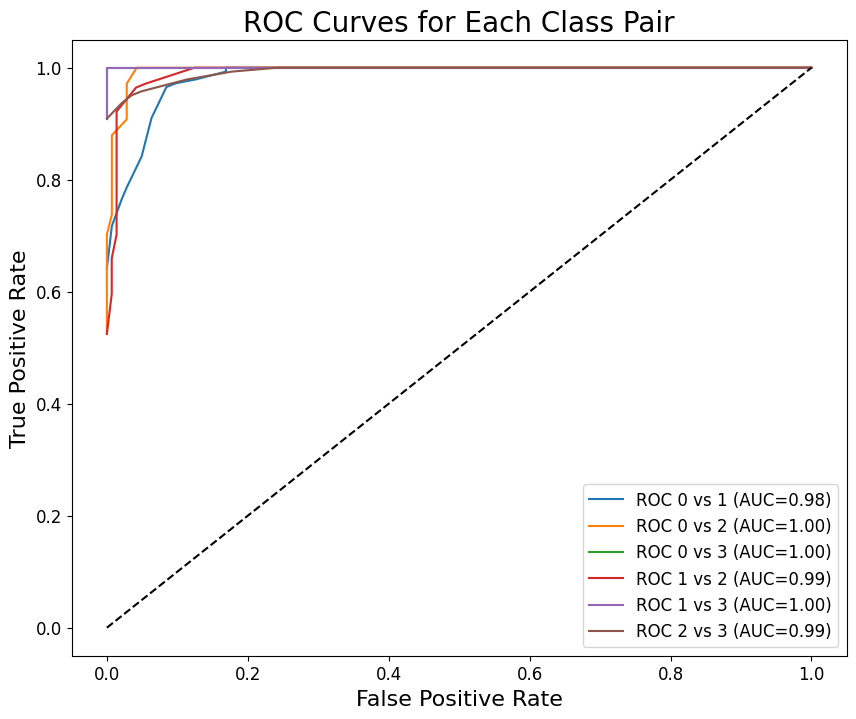

In [62]:
import numpy as np
import itertools
import matplotlib.pyplot as plt

def roc_curve(y_true, y_log):
    """
    This function plots the ROC curve and computes the AUC.

    Arguments:
    y_true: Ground truth labels with size N
    y_log: Probabilities produced by logistic regression model with size N

    Returns:
    auc: Area Under the Curve (AUC)
    tpr_l: List of true positive rate (TPR) values for each scanned threshold
    fpr_l: List of false positive rate (FPR) values for each scanned threshold
    thresholds: Scanned thresholds sorted in decreasing order

    """
    thresholds = reversed(sorted(set(y_log)))
    tpr_l, fpr_l = [], []

    for threshold in thresholds:
        y_thresholded = (y_log >= threshold)

        tp = np.sum(y_true & y_thresholded)
        tn = np.sum((~y_true) & (~y_thresholded))
        fp = np.sum((~y_true) & y_thresholded)
        fn = np.sum(y_true & (~y_thresholded))

        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
        fpr = fp / (tn + fp) if (tn + fp) > 0 else 0
        tpr_l.append(tpr)
        fpr_l.append(fpr)

    auc = np.trapz(tpr_l, fpr_l)
    return auc, tpr_l, fpr_l, list(thresholds)

def compute_roc_for_pairs(y_test, y_pred_probs):
    y_pred_probs = np.array(y_pred_probs)
    classes = np.unique(y_test)
    class_pairs = list(([0,1],[0,2],[0,3],[1,2],[1,3],[2,3]))
    
    plt.figure(figsize=(10, 8))

    for class_a, class_b in class_pairs:
        mask = (y_test == class_a) | (y_test == class_b)
        y_binary = (y_test[mask] == class_b)  
        
        y_probs = y_pred_probs[mask, class_b] 

        auc, tpr, fpr, _ = roc_curve(y_binary, y_probs)

        plt.plot(fpr, tpr, label=f"ROC {class_a} vs {class_b} (AUC={auc:.2f})")

    plt.plot([0, 1], [0, 1], 'k--')  
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves for Each Class Pair")
    plt.legend()
    plt.show()

compute_roc_for_pairs(y_train, soft_result)

<a name="task-13"></a>

## (1.3) [(index)](#index-task-13)

In [63]:

def gini_split_rf(n_features, X, y, cat_columns_dict):
    """
    Choose the best feature to split according to criterion.
    Args:
        n_features: number of sampled features.
        X: training features, of shape (N, p).
        y: vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
    Returns:
        (float, int, float): the minimized gini-index, the best feature index and value used in splitting.
    """

    # The added sampling step.
    columns = rng.choice(list(cat_columns_dict.keys()), n_features, replace=False)
    cat_columns_dict = {c: cat_columns_dict[c] for c in columns}

    min_gini_index, split_column, split_val = np.inf, 0, 0

    # Only scan through the sampled columns in `cat_columns_dict`.
    for column, categorical in cat_columns_dict.items():
        # skip column if samples are not separable by that column.
        if len(np.unique(X[:, column])) < 2:
            continue

        # search for the best splitting value for the given column.
        gini_index, val = gini_split_value(X, y, column, categorical)  ## <-- SOLUTION
        if gini_index < min_gini_index:
            min_gini_index, split_column, split_val = gini_index, column, val

    return min_gini_index, split_column, split_val

def build_tree_rf(n_features, X, y, cat_columns_dict, feature_names, depth, max_depth=10, min_samples_leaf=2):
    """Build the decision tree according to the data.
    Args:
        X: (np.array) training features, of shape (N, p).
        y: (np.array) vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
        feature_names (list): record the name of features in X in the original dataset.
        depth (int): current depth for this node.
        max_depth (int): maximum depth of the tree.
        min_samples_leaf (int): minimum number of samples in a leaf node.
    Returns:
        (dict): a dict denoting the decision tree (binary-tree). Each node has seven attributes:
          1. 'feature_name': The column name of the split.
          2. 'feature_index': The column index of the split.
          3. 'value': The value used for the split.
          4. 'categorical': indicator for categorical/numerical variables.
          5. 'majority_label': For leaf nodes, this stores the dominant label. Otherwise, it is None.
          6. 'left': The left sub-tree with the same structure.
          7. 'right' The right sub-tree with the same structure.
    """
    # include a clause for the cases where (i) all lables are the same, (ii) depth exceeded (iii) X is too small
    if len(np.unique(y)) == 1 or depth > max_depth or len(X) <= min_samples_leaf:
        return {'majority_label': majority_vote(y)}
    
    else:
        GI, split_column, split_val = gini_split_rf(n_features, X, y, cat_columns_dict)  ## <-- SOLUTION

        # If GI is infinity, it means that samples are not separable by the sampled features.
        if GI == np.inf:
            return {'majority_label': majority_vote(y)}
        
        categorical = cat_columns_dict[split_column]
        (X_l, y_l), (X_r, y_r) = split_samples(X, y, split_column, split_val, categorical) ## <-- SOLUTION
        
        # Compute Gini decrease
        N = len(y)
        GI_t = gini_index(y)
        GI_tL = gini_index(y_l) if len(y_l) > 0 else 0
        GI_tR = gini_index(y_r) if len(y_r) > 0 else 0
        p_L = len(y_l) / N if len(y_l) > 0 else 0
        p_R = len(y_r) / N if len(y_r) > 0 else 0
        delta_GI = GI_t - (p_L * GI_tL + p_R * GI_tR)
        
        # Store Gini importance
        if feature_names[split_column] in gini_importance_dict:
            gini_importance_dict[feature_names[split_column]] += delta_GI
        else:
            gini_importance_dict[feature_names[split_column]] = delta_GI

        return {
            'feature_name': feature_names[split_column],
            'feature_index': split_column,
            'value': split_val,
            'categorical': categorical,
            'majority_label': None,
            'left': build_tree_rf(n_features, X_l, y_l, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf),
            'right': build_tree_rf(n_features, X_r, y_r, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf)
        }
    
# EDIT THIS FUNCTION
def train_rf(B, X, y, cat_columns_dict, max_depth=10):
    """
    Train a random forest with B decision trees using bootstrapping.
    Args:
        B: number of decision trees.
        X: (pd.DataFrame) training features, shape (N, p).
        y: (pd.Series) training labels, shape (N,).
        cat_columns_dict: dictionary mapping feature indices to categorical/numerical indicator.
        max_depth: maximum depth of each decision tree.
    Returns:
        List of trained decision trees.
    """
    global gini_importance_dict
    gini_importance_dict = {}

    feature_names = X.columns.tolist()
    X = X.to_numpy()
    y = y.to_numpy()
    N, p = X.shape
    n_features = int(np.sqrt(p))  # Recommended value for classification
    
    training_indices = np.arange(N)
    trees = []

    for _ in range(B):
        # Bootstrap sample
        sample = rng.choice(training_indices, N, replace=True)
        X_sample = X[sample, :]
        y_sample = y[sample]
        
        # Train decision tree
        tree = build_tree_rf(n_features, X_sample, y_sample,
                             cat_columns_dict, feature_names, depth=0, max_depth=max_depth)
        trees.append(tree)

    return trees
    


In [64]:

def plot_gini_importance():
    max_importance = max(gini_importance_dict.values())
    normalized_importance = {k: (v / max_importance) * 100 for k, v in gini_importance_dict.items()}

    plt.figure(figsize=(10, 5))
    plt.bar(normalized_importance.keys(), normalized_importance.values())
    plt.xlabel("Features")
    plt.ylabel("Importance (%)")
    plt.xticks(rotation=45)
    plt.show()


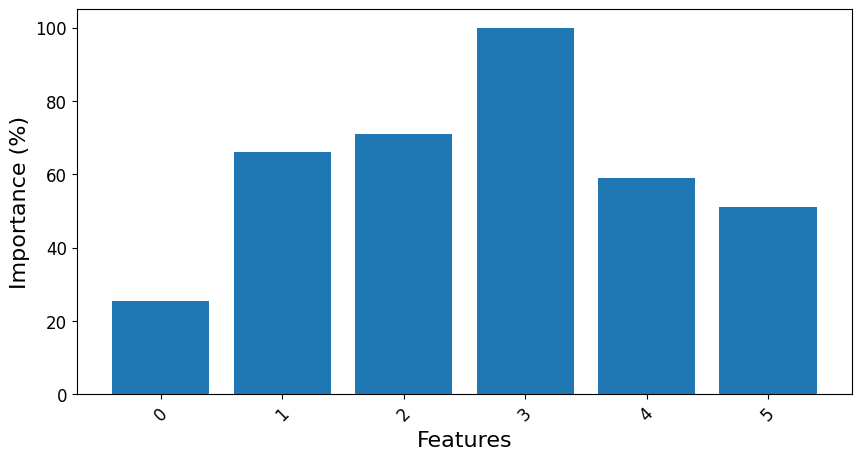

In [65]:
B = 20
n_features = np.sqrt(6) 
X1 = pd.DataFrame(X_train)
Y1 = pd.DataFrame(y_train)
rf = train_rf(B, X1, Y1, cat_columns_dict)
plot_gini_importance()

<a name="task-14"></a>

## (1.4) [(index)](#index-task-14)

In [66]:
# EDIT THIS FUNCTION
def classify(tree, x):
    """
    Classify a single sample with the fitted decision tree.
    Args:
        x: ((pd.Dataframe) a single sample features, of shape (p,).
    Returns:
        (int): predicted testing sample label.
    """
    if tree['majority_label'] is not None:
        return tree['majority_label']

    elif tree['categorical']:
        if x[tree['feature_index']] == tree['value']:
            # go to left branch
            return classify(tree['left'], x)
        else:
            # go to right branch
            return classify(tree['right'], x)

    else:

        if x[tree['feature_index']] < tree['value']: # <- SOLUTION
            # go to left branch
            return classify(tree['left'], x)  # <- SOLUTION
        else:
            # go to right branch
            return classify(tree['right'], x)  # <- SOLUTION
        
def predict(tree, X):
    """
    Predict classification results for X.
    Args:
        X: (pd.Dataframe) testing sample features, of shape (N, p).
    Returns:
        (np.array): predicted testing sample labels, of shape (N,).
    """
    if len(X.shape) == 1:
        return classify(tree, X)
    else:
        return np.array([classify(tree, x) for x in X])
    
## EDIT THIS FUNCTION
def tree_score(tree, X_test, y_test):
    y_pred = predict(tree, X_test) ## <-- SOLUTION
    return np.mean(y_pred==y_test)

def train_rf_OOB(B, X, y, cat_columns_dict, max_depth=10):
    """
    Train a random forest with B decision trees using bootstrapping and calculate the OOB error.
    Args:
        B: number of decision trees.
        X: (pd.DataFrame) training features, shape (N, p).
        y: (pd.Series) training labels, shape (N,).
        cat_columns_dict: dictionary mapping feature indices to categorical/numerical indicator.
        max_depth: maximum depth of each decision tree.
    Returns:
        List of trained decision trees and OOB error.
    """
    global gini_importance_dict
    gini_importance_dict = {}

    feature_names = X.columns.tolist()
    X = X.to_numpy()
    y = y.to_numpy()
    N, p = X.shape
    n_features = int(np.sqrt(p))  
    
    training_indices = np.arange(N)
    trees = []
    oob_predictions = np.zeros(N)
    oob_counts = np.zeros(N)

    for _ in range(B):
        sample = rng.choice(training_indices, N, replace=True)
        X_sample = X[sample, :]
        y_sample = y[sample]
        
        tree = build_tree_rf(n_features, X_sample, y_sample,
                             cat_columns_dict, feature_names, depth=0, max_depth=max_depth)
        trees.append(tree)

        # Track OOB predictions
        oob_sample = np.setdiff1d(training_indices, sample)  
        X_oob = X[oob_sample, :]
        y_oob = y[oob_sample]

        for idx in oob_sample:
            pred = predict(trees[-1], X[idx])  
            oob_predictions[idx] += pred
            oob_counts[idx] += 1

    oob_predictions /= oob_counts
    oob_error = np.mean(oob_predictions != y)

    return trees, oob_error


In [67]:
def find_optimal_B(X, y, cat_columns_dict, B_range=(10, 100, 10)):
    """
    Scan over a range of B values to find the optimal number of trees for the Random Forest.
    Args:
        X: training features
        y: training labels
        cat_columns_dict: categorical columns dictionary
        B_range: the range of B for optimisation
    Returns:
        optimal_B: the optimal number of trees.
    """
    best_oob_error = np.inf
    optimal_B = 0
    
    for B in range(B_range[0], B_range[1], B_range[2]):
        trees, oob_error = train_rf_OOB(B, X, y, cat_columns_dict)
        print(f'B={B}, OOB error={oob_error}')
        if oob_error < best_oob_error:
            best_oob_error = oob_error
            optimal_B = B
    
    return optimal_B


<a name="task-2"></a>

# Task 2: Binary classification with the Huberised Support Vector Machine [(index)](#index-task-2)

<a name="task-21"></a>

## (2.1) [(index)](#index-task-21)

$$
L (\mathbf{w}, b) = \frac{1}{2} \| \mathbf{w} \|^2 + \lambda \sum_{i=1}^N \mathbf{L}_{c} \bigg( 0, 1-y^{(i)} (\mathbf{x}^{(i)} \cdot \mathbf{w} + b) \bigg) \, with L_c
$$

In [ ]:
# EDIT THIS FUNCTION
def compute_loss(w, X, y, regul_strength=1e5):
    """
    Compute the loss function for linear SVM.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X (np.array): Input features.
        y (np.array): Labels.
        regul_strength (float): Regularisation parameter.

    Returns:
        loss (float): Loss function as given by the equation above.

    """

    n = X.shape[0]
    distances = 1 - y * (X @ w)  ## <-- SOLUTION
    distances[distances < 0] = 0  # equivalent to max(0, distance)
    hinge = distances.sum() ## <-- SOLUTION

    # calculate loss
    return 0.5 * np.dot(w, w) + regul_strength * hinge - 0.5 * w[-1] ** 2

<a name="task-22"></a>

## (2.2) [(index)](#index-task-22)

<a name="task-3"></a>

# Task 3: Regression with the Multi-Layer Perceptron [(index)](#index-task-3)

<a name="task-31"></a>

## (3.1) [(index)](#index-task-31)

<a name="task-32"></a>

## (3.2) [(index)](#index-task-32)